<img src='http://www-scf.usc.edu/~ghasemig/images/sharif.png' alt="SUT logo" width=500 height=300 align=center class="saturate" >

<br>
<font>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    Intelligent Analysis of Biomedical Images <br>
<font color=2565AE size=5>
    Computer Engineering Department <br>
    Fall 2025<br>
<font color=3C99D size=5>
    Practical Assignment 2 - Multi-Modality Classification with Convolutional Neural Networks <br>
<font color=696880 size=4>
Alireza Malekhosseini

**NAME:** Kian Tarakemeh

**STUDENT NUMBER:** 401110404


# Multi-Modality Classification with Convolutional Neural Networks (100 pts)

In this notebook we will build a PyTorch pipeline and run it on multiple imaging modalities using **MedMNIST** dataset:
- X-ray → **PneumoniaMNIST** (binary classification)
- CT → **OrganMNIST_Axial** (multi-class classification)
- Ultrasound → **BreastMNIST** (binary classification)

You'll practice:
1. Loading and inspecting datasets (with small sample grids)
2. **Preprocessing** and **modality-aware augmentations** (and visualizing before/after)
3. Training **two small models** (a Small CNN vs. a Small ResNet) on each dataset
4. Evaluating with **accuracy, ROC-AUC, confusion matrices**


In [1]:
#Uncomment if needed.
!pip install torch torchvision medmnist scikit-learn matplotlib pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.0 MB/s eta 0:00:00


In [2]:
import os, math, random
from dataclasses import dataclass
from typing import List, Dict
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms

from torchvision.transforms import InterpolationMode


from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from sklearn.preprocessing import label_binarize

from PIL import Image
from tqdm import tqdm

import medmnist
from medmnist import PneumoniaMNIST
from medmnist import BreastMNIST
from medmnist import OrganAMNIST  # instead of OrganMNISTAxial

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')


## 1) Reproducibility & Training Configuration (0 pts)


In [3]:

def set_seed(seed: int = 42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

from dataclasses import dataclass
@dataclass
class TrainConfig:
    img_size: int = 28
    batch_size: int = 256
    num_workers: int = 2
    use_amp: bool = True
CFG = TrainConfig(); CFG


TrainConfig(img_size=28, batch_size=256, num_workers=2, use_amp=True)


## 2) Load Datasets & Preview Samples (15 pts)



In this notebook, we work with selected datasets from **MedMNIST** — a collection of lightweight, standardized medical image datasets designed for quick experimentation, education, and benchmarking.  
We will explore **different medical imaging modalities** and **clinical classification tasks**:

---

### PneumoniaMNIST — Chest X-ray Classification
- **Modality:** X-ray (grayscale)
- **Task:** Binary classification  
  - `0 = NORMAL`  
  - `1 = PNEUMONIA`
- **Goal:** Detect pneumonia vs. healthy lungs  
- **Why we use it:** Introduces training a CNN on real clinical imaging with a simple, high-impact binary task.

 *Clinical note:* Data augmentations should preserve anatomical meaning (e.g., horizontal flip may be inappropriate in some cases).

---

### BreastMNIST — Breast Ultrasound Tumor Detection
- **Modality:** Ultrasound (grayscale)
- **Task:** Binary classification  
  - `0 = BENIGN`  
  - `1 = MALIGNANT`
- **Challenge:** Ultrasound images are noisy and low-contrast  

 *Class imbalance likely → consider weighted loss or sampling techniques.*

---

### OrganAMNIST — Organ Classification in Axial CT
- **Modality:** CT slices (grayscale)
- **Task:** Multi-class classification across 11 classes  
  (Bladder, Heart, Kidneys, Liver, Femurs, Lungs, Pancreas, Spleen…)
- **Goal:** Recognize which organ appears in each axial slice  

 *Some organs look very similar — useful for studying harder decision boundaries.*

In this notebook we will only train models on the first two datasets which are binary.

In [4]:
# label mappings for each dataset
LABEL_MAPPINGS = {
    'pneumonia': {
        'name': 'PneumoniaMNIST',
        'labels': {
            0: 'NORMAL',
            1: 'PNEUMONIA'
        }
    },
    'breast': {
        'name': 'BreastMNIST',
        'labels': {
            0: 'BENIGN',
            1: 'MALIGNANT'
        }
    },
    'organ_axial': {
        'name': 'OrganAMNIST',
        'labels': {
            0: 'Bladder',
            1: 'Femur-R',
            2: 'Femur-L',
            3: 'Heart',
            4: 'Kidney-R',
            5: 'Kidney-L',
            6: 'Liver',
            7: 'Lung-R',
            8: 'Lung-L',
            9: 'Pancreas',
            10: 'Spleen'
        }
    }
}

in this cell you should implement funciton for loading and visualizing the datasets.

100%|██████████| 4.17M/4.17M [00:07<00:00, 573kB/s]


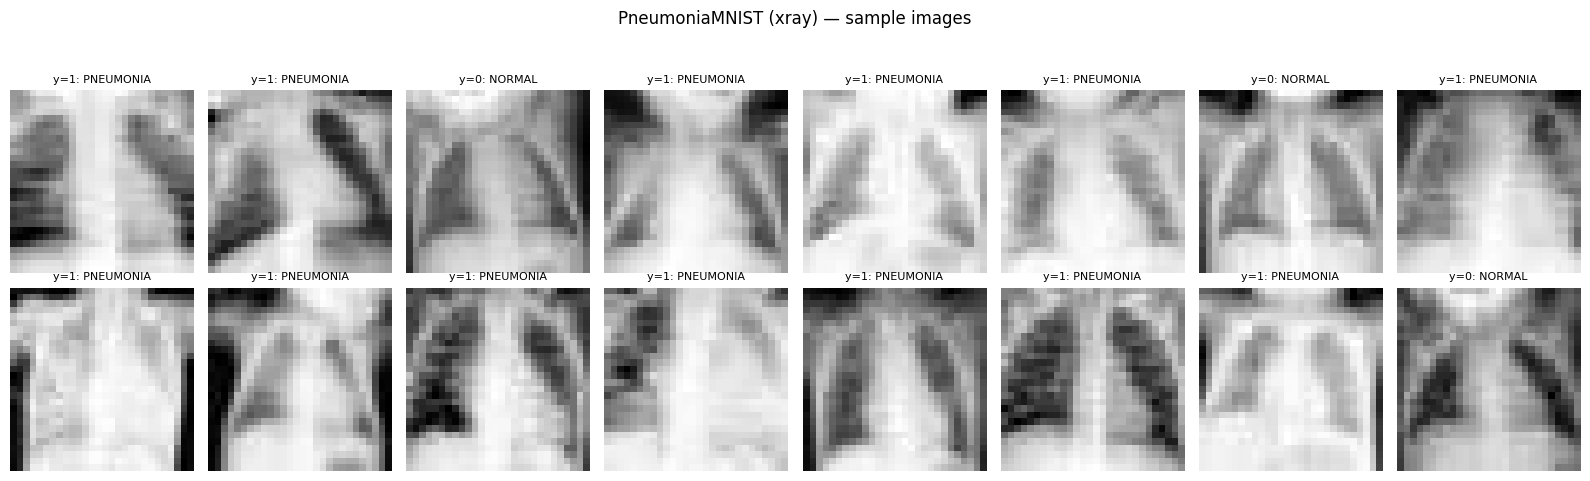

100%|██████████| 38.2M/38.2M [00:55<00:00, 690kB/s]


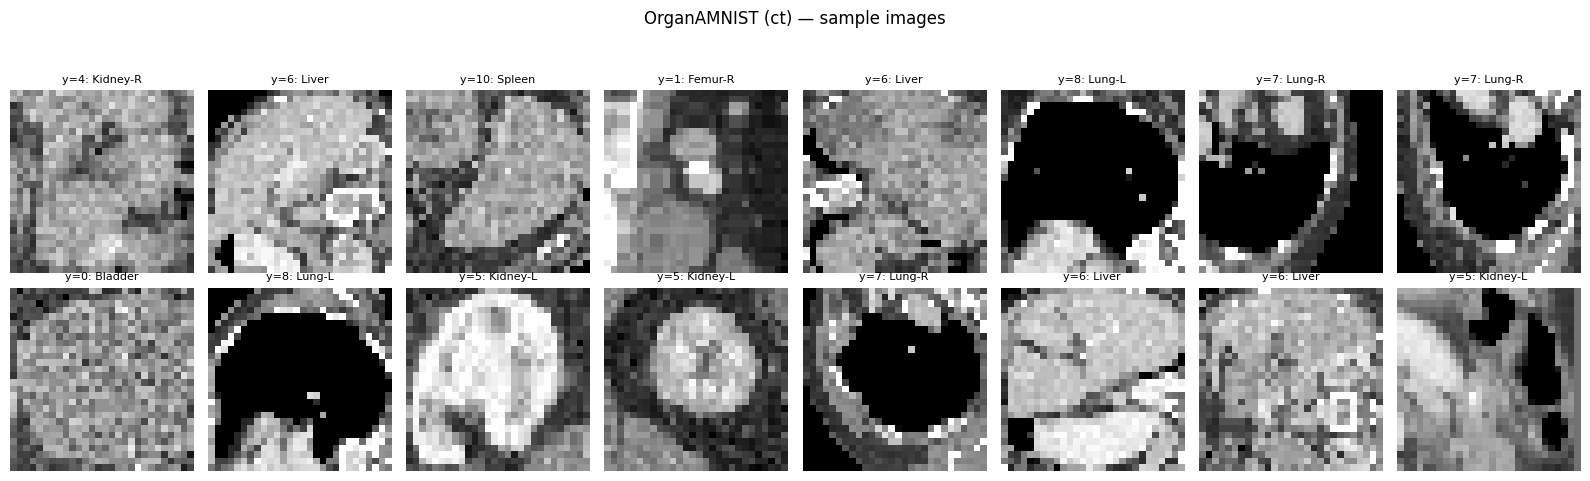

100%|██████████| 560k/560k [00:00<00:00, 701kB/s]


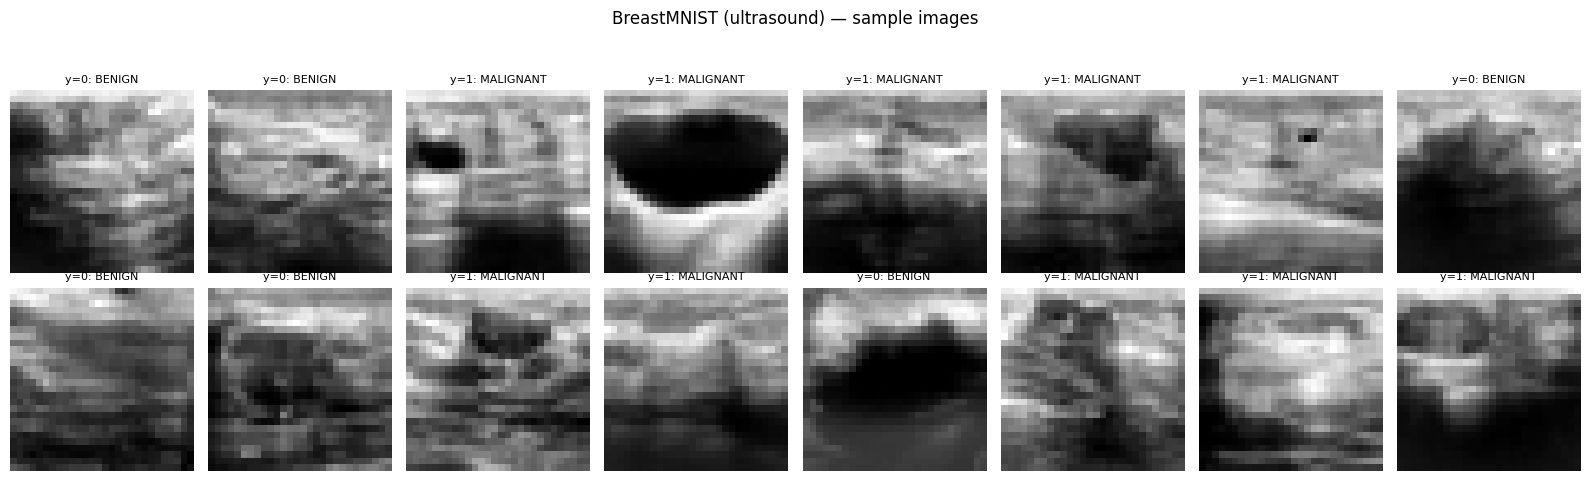

In [5]:
def load_medmnist(dataset_name: str, split: str, transform=None):
    """Select and instantiate the requested MedMNIST dataset split with the provided transform and image size,
     set the corresponding n_classes and modality strings, and raise an error for unknown names"""
    modality = None
    n_classes = None
    if dataset_name == 'pneumonia':
        ds = PneumoniaMNIST(split=split, transform=transform, download=True, as_rgb=False)
        n_classes = 2
        modality = 'xray'
    elif dataset_name == 'organ_axial':
        ds = OrganAMNIST(split=split, transform=transform, download=True, as_rgb=False)
        n_classes = 11
        modality = 'ct'
    elif dataset_name == 'breast':
        ds = BreastMNIST(split=split, transform=transform, download=True, as_rgb=False)
        n_classes = 2
        modality = 'ultrasound'
    else:
        raise ValueError("Unknown dataset")
    return ds, n_classes, modality

def show_samples(dataset_name: str, k: int = 16):
    """create a function for plotting some samples of the datasets along with their labels"""
    ds, n_classes, modality = load_medmnist(dataset_name, split='train', transform=None)
    label_map = LABEL_MAPPINGS[dataset_name]['labels']

    idxs = np.random.choice(len(ds), size=k, replace=False)

    cols = 8 if k >= 8 else k
    rows = int(math.ceil(k / cols))

    plt.figure(figsize=(2 * cols, 2.5 * rows))
    plt.suptitle(f"{LABEL_MAPPINGS[dataset_name]['name']} ({modality}) — sample images")

    for j, idx in enumerate(idxs):
        img, label = ds[idx]
        if isinstance(label, np.ndarray) or isinstance(label, list):
            label_int = int(label[0])
        elif torch.is_tensor(label):
            label_int = int(label.item())
        else:
            label_int = int(label)

        if isinstance(img, torch.Tensor):
            imshow = img.squeeze().numpy()
        else:
            imshow = np.array(img)

        ax = plt.subplot(rows, cols, j + 1)
        ax.imshow(imshow, cmap='gray')
        ax.axis('off')
        ax.set_title(f"y={label_int}: {label_map[label_int]}", fontsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


# Show samples with proper labels
for name in ['pneumonia','organ_axial','breast']:
    show_samples(name, k=16)

This cell visualizes label distributions across train, val, and test splits for a chosen MedMNIST dataset. Use these plots to inspect class balance before training.

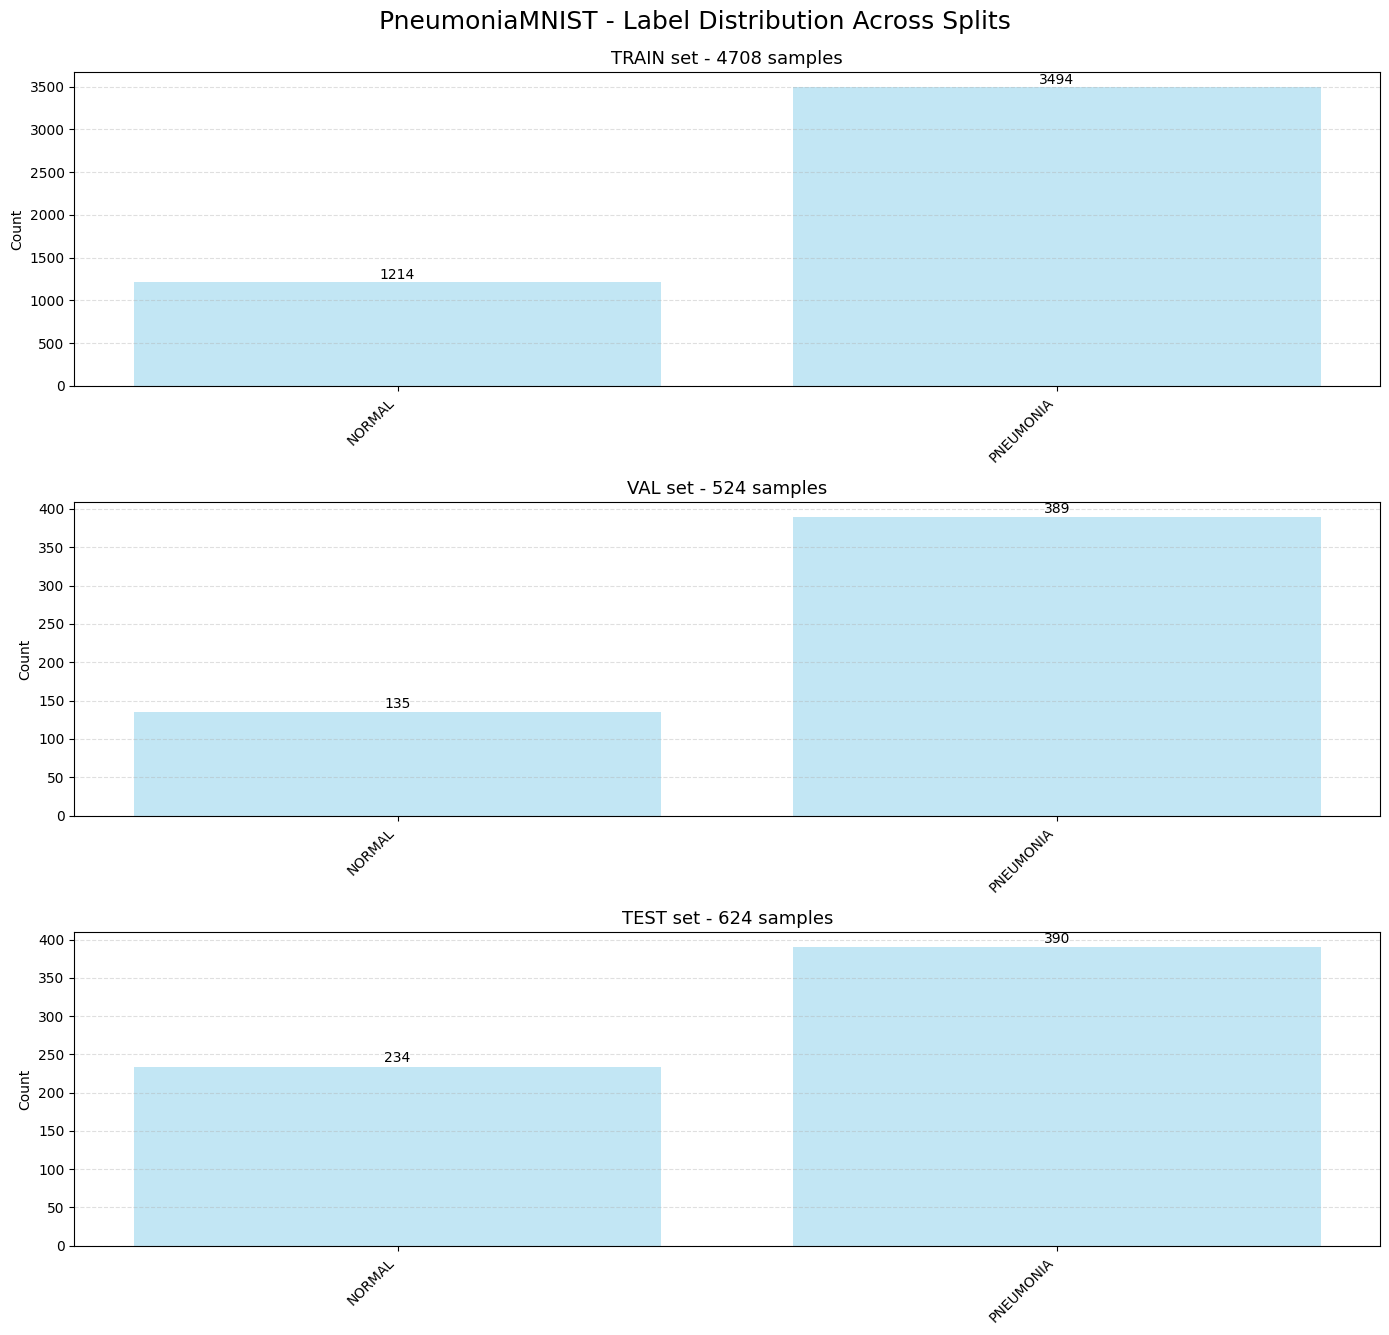

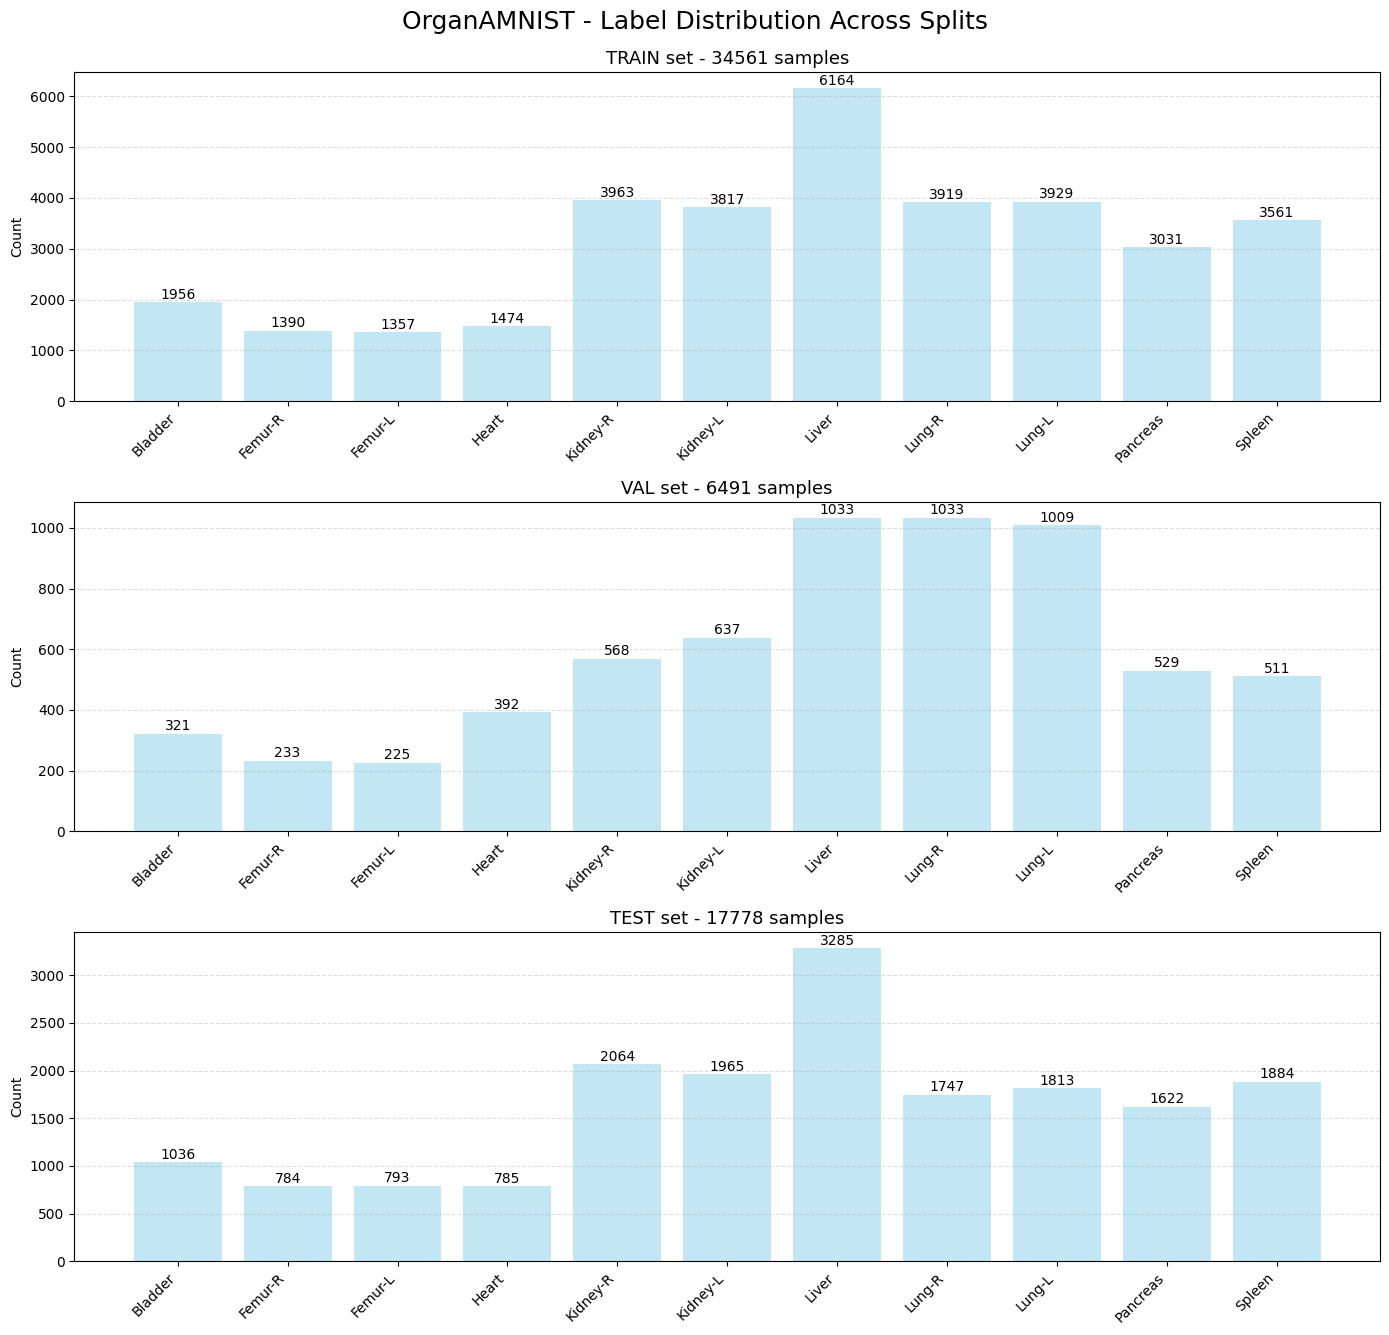

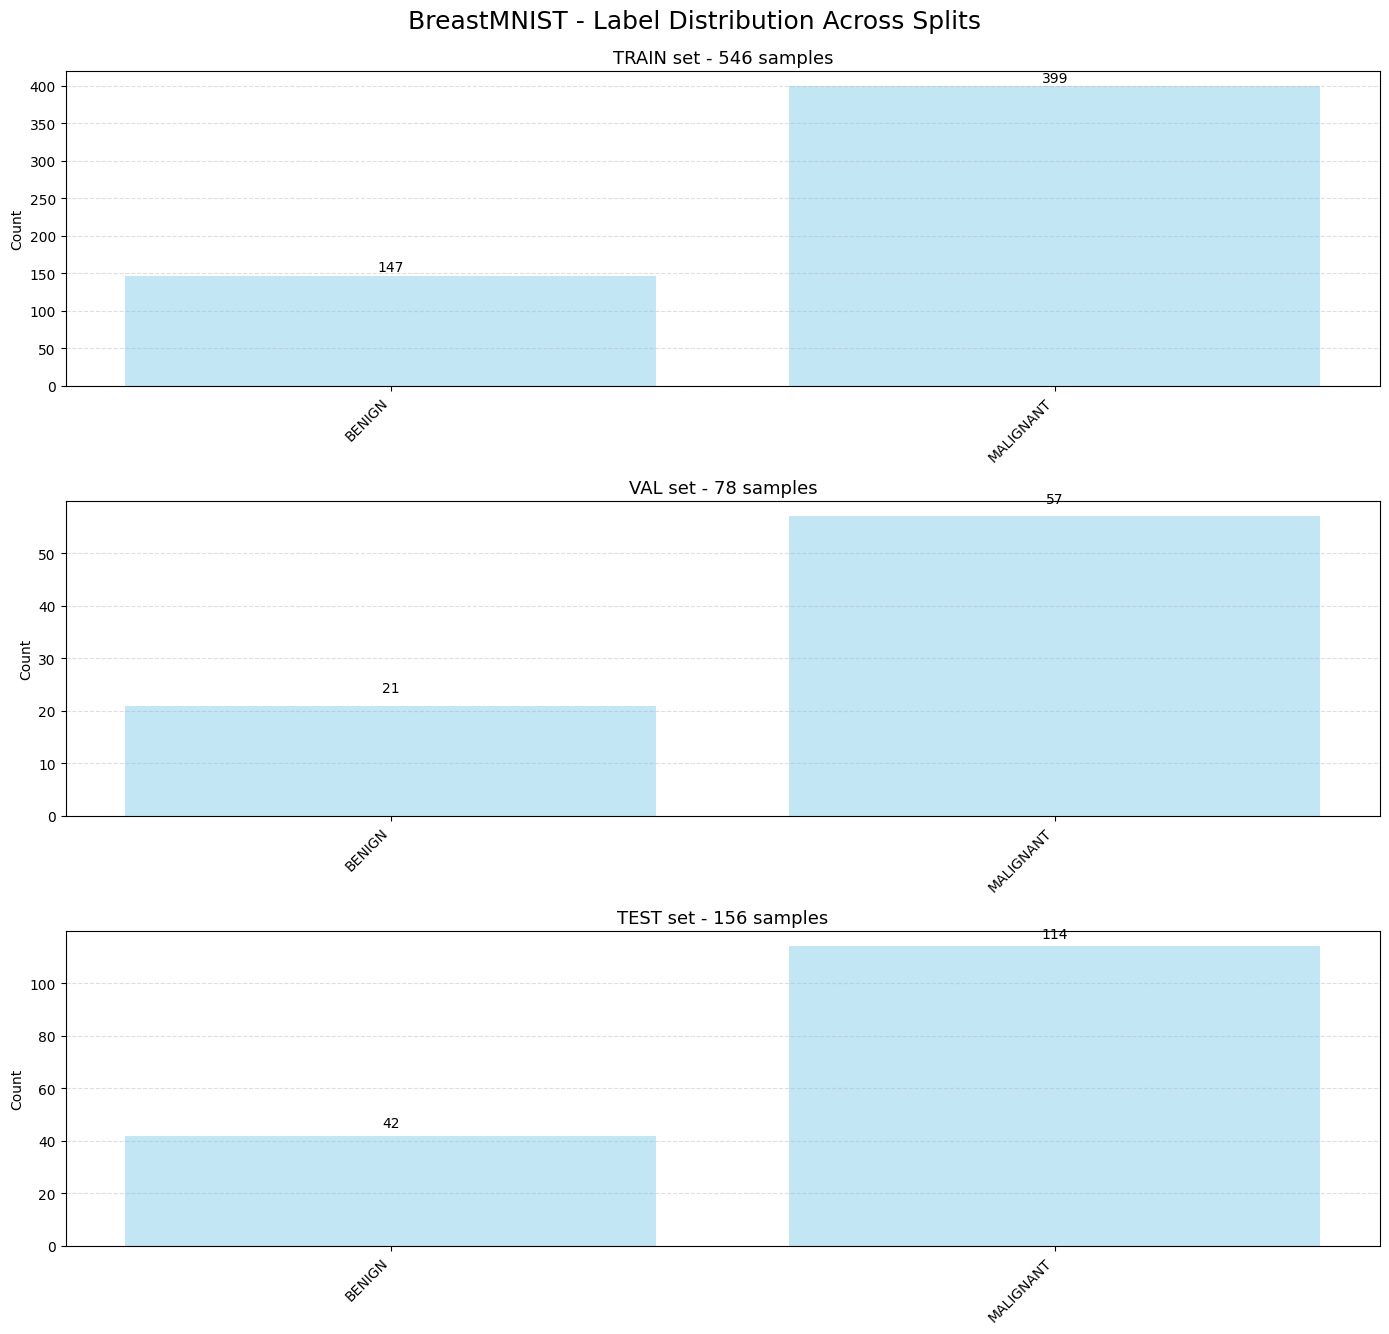

In [7]:
import matplotlib.pyplot as plt
import numpy as np

def plot_label_distribution(dataset_name: str):
    splits = ['train', 'val', 'test']
    tf = transforms.ToTensor()

    _, n_classes, _ = load_medmnist(dataset_name, split='train', transform=tf)
    label_map = LABEL_MAPPINGS[dataset_name]['labels']
    fig_title = LABEL_MAPPINGS[dataset_name]['name'] + " - Label Distribution Across Splits"

    split_counts = []
    split_sizes = []

    for split in splits:
        ds, _, _ = load_medmnist(dataset_name, split=split, transform=tf)
        labels = np.array(ds.labels).flatten()
        hist = np.bincount(labels, minlength=n_classes)
        split_counts.append(hist)
        split_sizes.append(len(ds))

    fig, axes = plt.subplots(3, 1, figsize=(14, 14))
    fig.suptitle(fig_title, fontsize=18, y=0.95)

    for ax, split, counts, size in zip(axes, splits, split_counts, split_sizes):
        x = np.arange(n_classes)

        bars = ax.bar(x, counts, alpha=0.5, color='skyblue')

        # Add numbers
        for rect, val in zip(bars, counts):
            ax.text(rect.get_x() + rect.get_width()/2,
                    rect.get_height() + 2,
                    str(val),
                    ha='center', va='bottom', fontsize=10)

        # x labels
        ax.set_xticks(x)
        ax.set_xticklabels(
            [label_map.get(i, '') for i in range(n_classes)],
            rotation=45,
            ha='right'
        )

        # title per subplot
        split_name = split.upper()
        ax.set_title(f"{split_name} set - {size} samples", fontsize=13)

        ax.set_ylabel("Count")
        ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()



# Plot all datasets
for name in ['pneumonia','organ_axial','breast']:
    plot_label_distribution(name)
    print("\n" + "="*80 + "\n")

**Question:** Looking at the plotted label distributions, which dataset/split shows the most severe class imbalance? Explain how this imbalance could affect training and evaluation for a classifier (mention at least two effects on learning and metrics)

**Answer:**

Dataset with Most Severe Imbalance: BreastMNIST (Train split)

Impact on Classifier Training and Evaluation
1. Accuracy as a Misleading Metric

When class distribution is heavily skewed, accuracy fails as a reliable performance indicator. A naive classifier that consistently predicts the majority class can achieve deceptively high accuracy (approximately 73% in this case) without learning any meaningful patterns about the minority class.

2. Optimization Bias During Training

The training process becomes biased toward the majority class since it dominates the loss function. The model develops a tendency to extract features primarily relevant to the majority class while treating minority class instances as noise or outliers, effectively marginalizing their importance.

***


**Question:** Pick one dataset with noticeable imbalance and propose a mitigation strategy (you can choose one or combine: weighted loss, oversampling, undersampling, data augmentation, synthetic examples, focal loss, or threshold calibration). Explain why you chose that approach and discuss one trade-off or limitation of your chosen method.

**Answer:**

Selected Dataset: BreastMNIST

Chosen Strategy: Weighted Cross-Entropy Loss

Implementation Details
The weighted cross-entropy loss assigns higher penalties to misclassifications of the minority class by setting class weights inversely proportional to their frequency in the dataset. This adjustment ensures that errors on underrepresented classes contribute more significantly to the overall loss.

Rationale
This approach effectively redirects the model’s attention toward the minority class during backpropagation and gradient updates. It accomplishes this without requiring modifications to the data pipeline or extending training time, making it both elegant and computationally efficient. The model is directly penalized more heavily for failing to correctly identify rare but critical cases.

Trade-off Consideration
The primary limitation is the risk of oversensitivity to the minority class. By amplifying the importance of minority samples, the model may become overly cautious and misclassify majority class instances as minority class (reduced precision on the majority class). This represents a classic precision-recall trade-off that requires careful tuning of the weight parameters.



## 3) Preprocessing & Modality-Aware Augmentations (30 pts)
 In this part you will implement safe/sensible augmentations for each modality.


Different medical imaging modalities require different preprocessing methods due
to the **nature of the signal** they capture:

- **X-ray** intensities depend on how much tissue blocks the X-ray beam. Contrast can vary a lot between scanners and patients, so we apply **CLAHE**, which enhances local contrast while avoiding strong noise amplification.

- **CT** images contain calibrated **Hounsfield Unit (HU)** values that represent real tissue density. We apply **windowing** to keep only clinically relevant intensity ranges (like soft tissue) and then normalize to a usable range for neural networks.

- **Ultrasound** uses echoes from sound waves, producing characteristic **speckle noise**. Too strong contrast or noise enhancement can destroy diagnostic structures. So we use **very mild** brightness adjustment to preserve anatomy.

> These augmentations are grounded in clinical physics — what works for natural images does not necessarily work for medical data. Each modality deserves modality-aware processing to keep the features meaningful and useful for diagnosis.



**Question:** Why is CLAHE suitable for X-ray but not usually applied to CT scans or ultrasound?

**Answer:**

CLAHE and X-ray Compatibility
CLAHE (Contrast Limited Adaptive Histogram Equalization) proves highly effective for X-ray imaging because X-rays are projection-based images where contrast levels vary substantially based on patient anatomy and scanner configuration. CLAHE addresses this variability by adaptively enhancing local contrast, revealing subtle anatomical structures that might otherwise remain obscured.

Limitations with Other Modalities
1. CT Scans: Preservation of Quantitative Information

CT imaging relies on calibrated pixel values that represent precise physical measurements, specifically Hounsfield Units (HU) or tissue density values. CLAHE modifies pixel intensities based on local statistical distributions, which fundamentally distorts these quantitative relationships and eliminates the physical meaning encoded in the data. For CT scans, windowing techniques are preferred as they allow selective visualization of specific density ranges without corrupting the underlying calibrated measurements.

2. Ultrasound: Amplification of Speckle Artifacts

Ultrasound images inherently contain speckle noise as a characteristic artifact of the imaging process. Since CLAHE functions as an aggressive contrast enhancement algorithm, applying it to ultrasound would amplify this noise alongside actual anatomical features. This amplification potentially obscures genuine anatomical structures and significantly diminishes diagnostic accuracy by making it harder to distinguish signal from noise.

In [8]:
import cv2
import torchvision.transforms.functional as TF

class MildCLAHE:
    """Mild Contrast Limited Adaptive Histogram Equalization for X-rays"""
    def __init__(self, clip_limit=2.0, grid_size=(8,8)):
        self.clip_limit = clip_limit
        self.grid_size = grid_size

    def __call__(self, img):
        """apply a mild CLAHE-based local-contrast enhancement using OpenCV, then return the result
         in the same tensor/array type and shape as the input."""
        is_pil = isinstance(img, Image.Image)
        is_tensor = isinstance(img, torch.Tensor)

        if is_pil:
            img_np = np.array(img)
        elif is_tensor:
            img_np = img.permute(1, 2, 0).numpy()
            if img_np.max() <= 1.0:
                img_np = (img_np * 255).astype(np.uint8)
            else:
                img_np = img_np.astype(np.uint8)
        else:
            img_np = np.array(img)

        if img_np.ndim == 3 and img_np.shape[2] == 1:
            img_np = img_np[:, :, 0]

        clahe = cv2.createCLAHE(clipLimit=self.clip_limit, tileGridSize=self.grid_size)
        augmented_np = clahe.apply(img_np)

        if augmented_np.ndim == 2:
            augmented_np = np.expand_dims(augmented_np, axis=2) # Back to (H, W, C)

        if is_pil:
            if augmented_np.shape[2] == 1:
                augmented_np = augmented_np[:, :, 0]
            augmented = Image.fromarray(augmented_np)
        elif is_tensor:
            augmented = torch.from_numpy(augmented_np).permute(2, 0, 1).float() / 255.0
        else:
            augmented = augmented_np

        return augmented

class CTIntensityStandardization:
    """CT intensity windowing and standardization"""
    def __init__(self, window_center=40, window_width=80):
        self.window_center = window_center
        self.window_width = window_width

    def __call__(self, img):
        """applies an Intensity Standardization on the CT images: normalize the  values to [0,1], and return the result with
         the same type/shape as the input"""
        min_val = self.window_center - (self.window_width / 2)
        max_val = self.window_center + (self.window_width / 2)

        if isinstance(img, torch.Tensor):
            augmented = torch.clamp(img, min=min_val, max=max_val)
            augmented = (augmented - min_val) / (max_val - min_val)
        else:
            img_np = np.array(img).astype(np.float32)
            augmented = np.clip(img_np, min_val, max_val)
            augmented = (augmented - min_val) / (max_val - min_val)

            if isinstance(img, Image.Image):
                augmented = Image.fromarray((augmented * 255).astype(np.uint8))

        return augmented

class UltrasoundSafeAugment:
    """Ultrasound-specific augmentations that preserve diagnostic features"""
    def __init__(self, p=0.3):
        self.p = p

    def __call__(self, img):
        """With probability p, apply subtle, ultrasound-appropriate augmentations that preserve anatomical and texture information.
         You can use slight brightness or contrast shifts, minimal gamma correction, soft blurring, or elastic deformations
         that mimic probe pressure. Avoid aggressive noise, rotations, or strong filtering that could distort key diagnostic patterns."""
        if random.random() < self.p:
            aug_type = random.choice(['brightness', 'contrast', 'blur', 'gamma'])

            if aug_type == 'brightness':
                factor = random.uniform(0.9, 1.1)
                img = TF.adjust_brightness(img, factor)

            elif aug_type == 'contrast':
                factor = random.uniform(0.9, 1.1)
                img = TF.adjust_contrast(img, factor)

            elif aug_type == 'blur':
                img = TF.gaussian_blur(img, kernel_size=3, sigma=[0.5, 0.5])

            elif aug_type == 'gamma':
                gamma = random.uniform(0.9, 1.1)
                img = TF.adjust_gamma(img, gamma)

        return img


class To3CH:
    """If the input is single-channel, expands it to a 3-channel image suitable for 3-channel networks"""
    def __call__(self, img: torch.Tensor):
        if img.ndim == 2:
            img = img.unsqueeze(0)
        if img.shape[0] == 1:
            img = img.repeat(3, 1, 1)
        return img

**Question:** Why must augmentations for ultrasound images remain subtle compared to those for modalities like X-rays or CT? Justify the Augmentations you chose for Ultrasound and explain.

**Answer:**

Core Principle

Ultrasound imaging fundamentally depends on tissue texture patterns and directional physics. Aggressive augmentations such as strong contrast adjustments or large rotations would distort these diagnostic textures or introduce physically implausible shadow patterns that confuse the model.

Justified Augmentation Choices

Brightness/Gamma/Contrast Adjustments: Simulate real-world variability in sonographer gain settings during image acquisition

Soft Blur: Represents natural motion artifacts from patient breathing or minor probe movement

Key Rationale

These subtle transformations reflect authentic clinical variations that occur during actual scanning procedures, without compromising the underlying anatomical topology or violating the physical principles of ultrasound wave propagation.

/tmp/ipython-input-451984818.py:58: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(f"Original (y={int(y)})")


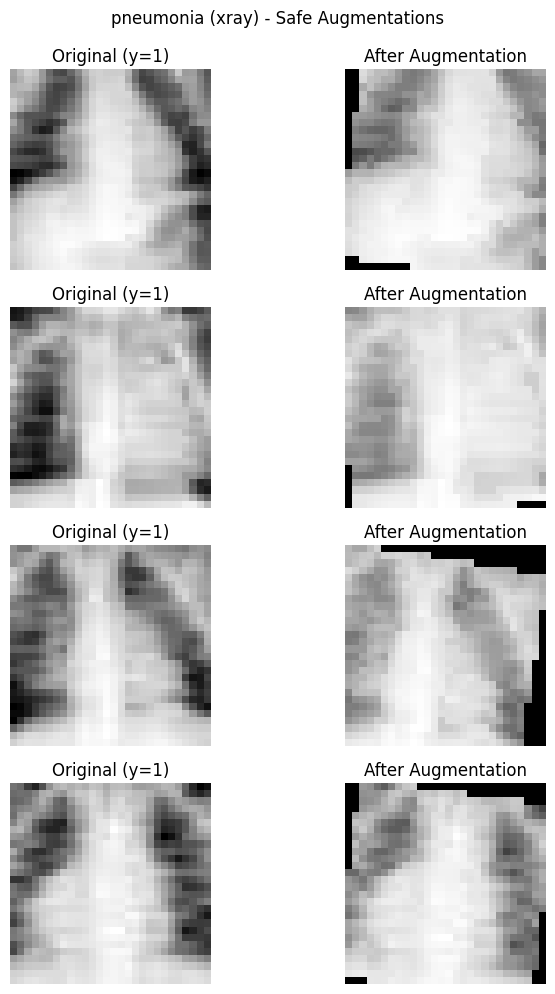

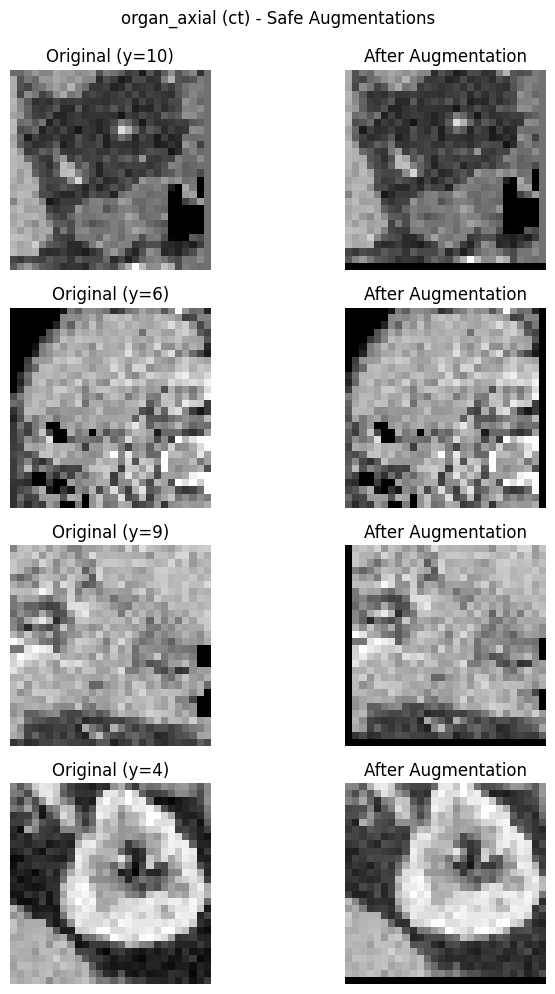

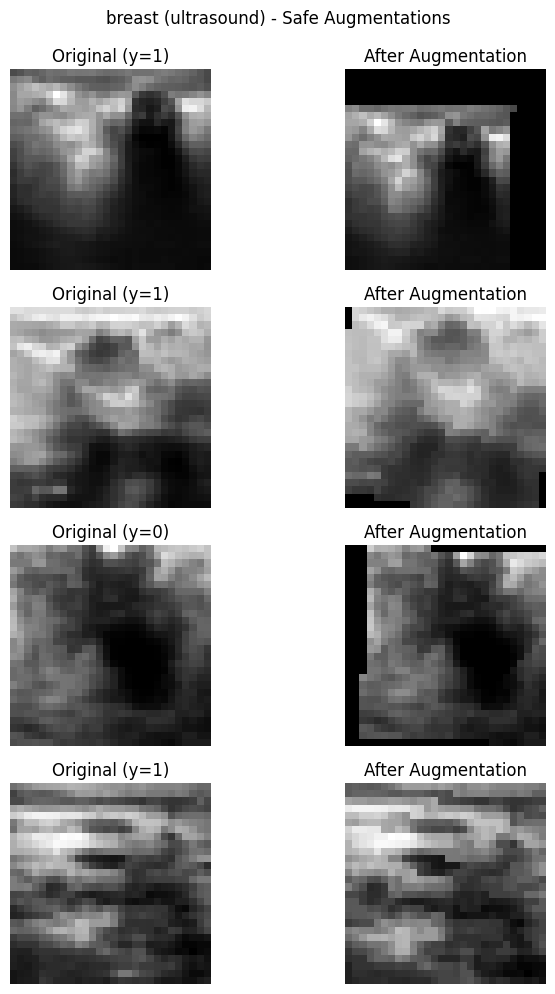

In [9]:
def get_transforms(modality: str, is_train: bool):
    """Combine base, augmentation, and post-processing transforms carefully, ensuring the resulting pipeline
     keeps intensity scales consistent for learning. you should use your implemented augmentations class"""
    base = [
        transforms.ToTensor(),
        To3CH()
    ]

    aug = []


    post = [
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
    ]

    if is_train:
        if modality == 'pneumonia' or modality == 'xray':
            aug = [
                transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1))
            ]

        elif modality == 'organ_axial' or modality == 'ct':
            aug = [
                CTIntensityStandardization(),
                transforms.RandomAffine(degrees=0, translate=(0.05, 0.05))
            ]

        elif modality == 'breast' or modality == 'ultrasound':
            aug = [
                UltrasoundSafeAugment(p=0.5),
                transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.85, 1.15))
            ]

    elif not is_train and (modality == 'organ_axial' or modality == 'ct'):
         aug = [CTIntensityStandardization()]

    return transforms.Compose(base + aug + post)

def demo_augmentations(dataset_name: str, modality: str, n: int = 6):
    """Demo function to show modality-aware augmentations"""
    ds_raw, _, _ = load_medmnist(dataset_name, 'train', transform=None)
    tf_train = get_transforms(modality, is_train=True)

    idxs = np.random.choice(len(ds_raw), size=min(n, len(ds_raw)), replace=False)
    plt.figure(figsize=(8, 2.5*n))

    for i, idx in enumerate(idxs):
        x_raw, y = ds_raw[idx]

        x_tensor_before = transforms.ToTensor()(x_raw)
        before = x_tensor_before[0].numpy() if x_tensor_before.shape[0] == 1 else x_tensor_before.numpy().squeeze()

        x_aug = tf_train(x_raw)
        after = x_aug[0].detach().cpu().numpy() if x_aug.shape[0] == 3 else x_aug.detach().cpu().numpy().squeeze()

        plt.subplot(n, 2, 2*i+1)
        plt.imshow(before, cmap='gray')
        plt.title(f"Original (y={int(y)})")
        plt.axis('off')

        plt.subplot(n, 2, 2*i+2)
        plt.imshow(after, cmap='gray')
        plt.title("After Augmentation")
        plt.axis('off')

    plt.suptitle(f"{dataset_name} ({modality}) - Safe Augmentations", y=0.99)
    plt.tight_layout()
    plt.show()

demo_augmentations('pneumonia', 'xray', n=4)
demo_augmentations('organ_axial', 'ct', n=4)
demo_augmentations('breast', 'ultrasound', n=4)

**Question:** How could modality-specific augmentation improve generalization to new hospitals or scanners?

**Answer:**

Concept

Modality-specific augmentation replicates natural technical variations between different hardware manufacturers (e.g., GE vs. Siemens) and acquisition protocols.

Implementation Examples

For X-rays/Ultrasounds: Brightness, gamma, and subtle blurring adjustments simulate differences in exposure settings, detector sensitivity, and operator technique across different systems.

Generalization Benefit

During training, the model encounters these hardware-induced variations and learns to focus on anatomical features (shapes, textures) rather than memorizing scanner-specific noise patterns or contrast characteristics. This approach prevents domain overfitting to a single hospital’s equipment.

**Question:** If we applied random rotation or strong geometric warping to organ CT slices, what anatomical assumptions might be violated?

**Answer:**

1. Left/Right Asymmetry

Human anatomy lacks symmetry—liver positioning on the right, spleen/stomach on the left. Horizontal flipping would create anatomically impossible configurations, confusing the model with non-existent organ arrangements.

2. Standardized Patient Positioning

Axial CT scans maintain consistent patient orientation (supine position). Vertical flips or large rotations would generate orientations that never occur clinically, forcing the model to learn irrelevant spatial variations.

3. Organ Volumetrics

Strong warping distorts organ size and shape measurements. Since precise structural dimensions are critical diagnostic features for detecting malignancies, warping destroys this essential metric information.


## 4) DataLoaders


In [10]:
def make_dataloaders(dataset_name: str, cfg, batch_size = None):
    final_batch_size = cfg.batch_size
    if batch_size is not None:
        final_batch_size = batch_size
    modality = {'pneumonia':'xray', 'organ_axial':'ct', 'breast':'ultrasound'}[dataset_name]
    tf_train = get_transforms(modality, is_train=True)
    tf_eval  = get_transforms(modality, is_train=False)
    train_ds, n_classes, _ = load_medmnist(dataset_name, 'train', tf_train)
    val_ds, _, _ = load_medmnist(dataset_name, 'val',   tf_eval)
    test_ds, _, _ = load_medmnist(dataset_name, 'test',  tf_eval)
    train_loader = DataLoader(train_ds, batch_size=final_batch_size, shuffle=True,  num_workers=cfg.num_workers)
    val_loader   = DataLoader(val_ds,   batch_size=final_batch_size, shuffle=False, num_workers=cfg.num_workers)
    test_loader  = DataLoader(test_ds,  batch_size=final_batch_size, shuffle=False, num_workers=cfg.num_workers)
    return train_loader, val_loader, test_loader, n_classes, modality



## 5) Models: SmallCNN vs SmallResNet (20 pts)


### What Makes ResNet Different

ResNet (Residual Network) introduced the concept of **skip connections** — a mechanism that allows information to flow directly from earlier to later layers.  
Instead of each block learning an entirely new transformation, it learns only the **residual**, or the *difference* from the input.  

This simple idea helps:
-  Prevent **vanishing gradients** in deep networks  
-  Improve **training stability** and **convergence speed**  
-  Allow the network to be **much deeper** without losing accuracy  

>  In essence, ResNet learns *what to change*, not *what to rebuild* — enabling efficient learning in very deep architectures.

You can refer to the paper for a better insight. In this part you will implement a small Resnet along with a simple CNN and compare them after training.

 **Reference:**  
He, K., Zhang, X., Ren, S., & Sun, J. (2015). *Deep Residual Learning for Image Recognition*.  
[https://arxiv.org/abs/1512.03385](https://arxiv.org/abs/1512.03385)


In [11]:

class SmallCNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        """Implement a simple CNN for image classification.
        Use stacked convolutional layers, optionally with batch normalization and activation functions.
        Include some downsampling (pooling) to reduce spatial dimensions.
        Aggregate features before the final fully connected layer."""

        self.net = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.net(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        """Implement a ResNet-style residual block with two conv layers and a skip connection.
        Handle changes in channels or resolution with the skip path."""
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )
    def forward(self,x):
        """Handle skip connection in forward"""
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out += self.shortcut(identity)

        out = self.relu(out)
        return out

class SmallResNet(nn.Module):
    def __init__(self, num_classes:int):
        super().__init__()
        """Stack multiple residual blocks with increasing channels and downsampling.
        Use a stem conv layer, global pooling, and a linear layer for classification."""
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )

        self.layer1 = BasicBlock(in_ch=16, out_ch=16, stride=1)
        self.layer2 = BasicBlock(in_ch=16, out_ch=32, stride=2)
        self.layer3 = BasicBlock(in_ch=32, out_ch=64, stride=2)

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Linear(64, num_classes)
    def forward(self,x):
        out = self.stem(x)

        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)

        out = self.pool(out)
        out = out.view(out.size(0), -1)
        return self.head(out)



## 6) Training & Evaluation Utilities (15 pts)


In [21]:
from torch.cuda.amp import autocast
def train_one_epoch(model, loader, optimizer, scaler=None):
    """Run a single training epoch: ensure targets are integer class tensors,
    compute logits and cross-entropy loss (Or other losses as you wish), perform backprop and optimizer step
    (you can also use AMP / GradScaler), and accumulate batch loss and accuracy.
     Remember to handle target dtype/shape (long, flattened), and use scaler when using mixed precision."""

    model.train()
    total=correct=0
    loss_sum=0.0

    criterion = nn.CrossEntropyLoss()

    device = next(model.parameters()).device

    for x,y in tqdm(loader, leave=False):
        x = x.to(device)
        y = y.squeeze().long().to(device)

        optimizer.zero_grad()

        if scaler is not None:
            with torch.amp.autocast('cuda'):
                logits = model(x)
                loss = criterion(logits, y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

        loss_sum += loss.item() * x.size(0)

        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += x.size(0)

    return loss_sum/total, correct/total

@torch.no_grad()
def evaluate(model, loader, n_classes):
  """Evaluate the model without gradients: set model to eval mode, loop over the dataset, compute logits and cross-entropy loss,
   collect predicted probabilities and true targets for downstream metrics, and compute accuracy.
   store probs_all and targets_all for metric computation."""
  model.eval()
  total=correct=0
  loss_sum=0.0
  probs_all=[]
  targets_all=[]

  criterion = nn.CrossEntropyLoss()
  device = next(model.parameters()).device

  for x,y in loader:
      x = x.to(device)
      y = y.squeeze().long().to(device)

      logits = model(x)
      loss = criterion(logits, y)

      loss_sum += loss.item() * x.size(0)

      preds = logits.argmax(dim=1)
      correct += (preds == y).sum().item()
      total += x.size(0)

      probs = torch.softmax(logits, dim=1)
      probs_all.append(probs.cpu().numpy())
      targets_all.append(y.cpu().numpy())

  probs_all=np.concatenate(probs_all,0)
  targets_all=np.concatenate(targets_all,0)

  """compute AUC differently for binary vs. multiclass (use label-binarization for multiclass and a suitable averaging strategy)."""
  try:
      if n_classes == 2:
          auc = roc_auc_score(targets_all, probs_all[:, 1])
      else:
          auc = roc_auc_score(targets_all, probs_all, multi_class='ovr', average='macro')
  except ValueError:
      auc = 0.0
  return loss_sum/total, correct/total, probs_all, targets_all, auc


In [13]:
def plot_curves(hist, title='Curves'):
    ep=range(1,len(hist['train_loss'])+1)
    plt.figure(); plt.plot(ep,hist['train_loss'],label='train loss'); plt.plot(ep,hist['val_loss'],label='val loss')
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.title(title); plt.legend(); plt.show()
    plt.figure(); plt.plot(ep,hist['train_acc'],label='train acc'); plt.plot(ep,hist['val_acc'],label='val acc')
    plt.xlabel('epoch'); plt.ylabel('acc'); plt.title(title); plt.legend(); plt.show()

def plot_confusion(y_true,y_pred,classes,normalize=False,title='Confusion'):
    cm=confusion_matrix(y_true,y_pred,normalize='true' if normalize else None)
    fig,ax=plt.subplots(figsize=(5,5)); im=ax.imshow(cm,interpolation='nearest'); ax.figure.colorbar(im,ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=classes, yticklabels=classes,
           ylabel='True', xlabel='Predicted', title=title+(' (norm)' if normalize else ''))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    thr=cm.max()/2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j,i, f"{cm[i,j]:.2f}" if normalize else int(cm[i,j]),
                    ha='center', va='center', color='white' if cm[i,j]>thr else 'black')
    fig.tight_layout(); plt.show()



## 8) Train & Compare on Each Modality (10 pts)

In this section you will implement the full experiment of training, validation and testing the models on specific models and datasets.

In [25]:
import copy
def train(dataset_name: str, cfg, model_kind='cnn', epochs= None, batch_size = None, lr = 1e-4, weight_decay = 1e-4, early_stop_patience =4):
    """Set up data loaders and model, define optimizer and optional AMP, then train and validate for several epochs while tracking performance.
    Implement early stopping and save the best model. Finally, evaluate on the test set and return the trained model, metrics, and results."""

    train_loader, val_loader, test_loader, n_classes, modality = make_dataloaders(dataset_name, cfg, batch_size)
    print(f"Starting training: {dataset_name} ({modality}) | Model: {model_kind.upper()}")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    if model_kind == 'cnn':
        model = SmallCNN(num_classes=n_classes).to(device)
    elif model_kind == 'resnet':
        model = SmallResNet(num_classes=n_classes).to(device)
    else:
        raise ValueError("Invalid model_kind")

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scaler = torch.amp.GradScaler('cuda')

    hist = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [], 'val_auc': []
    }

    best_val_auc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(epochs):
        t_loss, t_acc = train_one_epoch(model, train_loader, optimizer, scaler)

        v_loss, v_acc, _, _, v_auc = evaluate(model, val_loader, n_classes)

        hist['train_loss'].append(t_loss)
        hist['train_acc'].append(t_acc)
        hist['val_loss'].append(v_loss)
        hist['val_acc'].append(v_acc)
        hist['val_auc'].append(v_auc)

        print(f"Ep {epoch+1}/{epochs} | train_loss: {t_loss:.4f} | trian_acc: {t_acc:.3f} | val_loss: {v_loss:.4f} | val_acc: {v_acc:.3f} | AUC: {v_auc:.3f}")

        if v_auc > best_val_auc:
            best_val_auc = v_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= early_stop_patience:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break

    model.load_state_dict(best_model_wts)

    test_loss, test_acc, test_probs, test_targets, test_auc = evaluate(model, test_loader, n_classes)
    print(f"TEST | loss {test_loss:.4f} acc {test_acc:.3f} auc {test_auc:.3f}")
    return {'model':model, 'hist':hist,'n_classes':n_classes,'modality':modality,
            'test_loader':test_loader,'test_probs':test_probs,'test_targets':test_targets,
            'test_metrics':{'loss':test_loss,'acc':test_acc,'auc':test_auc}}


## 9) Run the experiments (10 pts)


==== PNEUMONIA — SmallCNN ====
Starting training: pneumonia (xray) | Model: CNN


Ep 1/20 | train_loss: 0.6557 | trian_acc: 0.699 | val_loss: 0.6140 | val_acc: 0.750 | AUC: 0.814


Ep 2/20 | train_loss: 0.5795 | trian_acc: 0.789 | val_loss: 0.4872 | val_acc: 0.782 | AUC: 0.914


Ep 3/20 | train_loss: 0.5302 | trian_acc: 0.818 | val_loss: 0.4223 | val_acc: 0.813 | AUC: 0.936


Ep 4/20 | train_loss: 0.4851 | trian_acc: 0.849 | val_loss: 0.3848 | val_acc: 0.840 | AUC: 0.942


...

Ep 16/20 | train_loss: 0.2805 | trian_acc: 0.917 | val_loss: 0.2696 | val_acc: 0.906 | AUC: 0.964


Ep 17/20 | train_loss: 0.2747 | trian_acc: 0.915 | val_loss: 0.2672 | val_acc: 0.908 | AUC: 0.968


Ep 18/20 | train_loss: 0.2663 | trian_acc: 0.921 | val_loss: 0.2661 | val_acc: 0.908 | AUC: 0.968


Ep 19/20 | train_loss: 0.2594 | trian_acc: 0.923 | val_loss: 0.2549 | val_acc: 0.908 | AUC: 0.968


Ep 20/20 | train_loss: 0.2538 | trian_acc: 0.921 | val_loss: 0.2522 | val_acc: 0.916 | AUC: 0.970
TEST | loss 0.3371 acc 0.869 auc 0.940


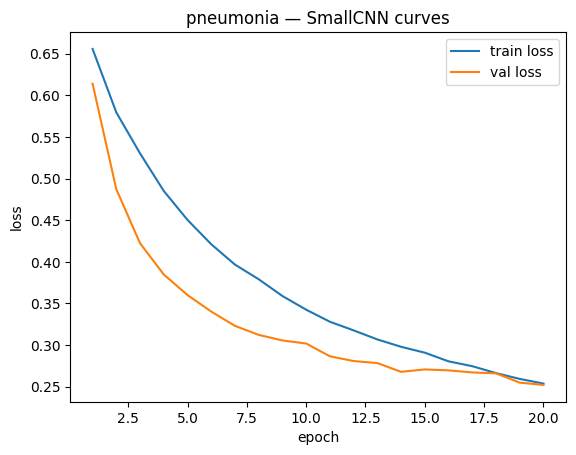

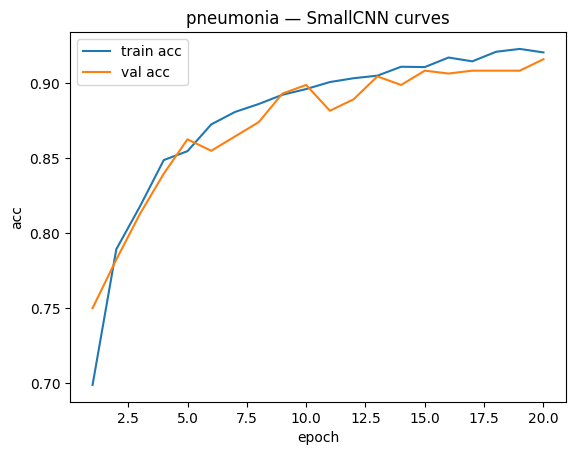

In [26]:
experiments = {}
num_epochs = 20


for ds in ['pneumonia']:
    print(f"\n==== {ds.upper()} — SmallCNN ====")

    res_cnn = train(
        dataset_name=ds,
        cfg=CFG,
        model_kind='cnn',
        epochs=num_epochs,
        batch_size=256,
    )

    if ds not in experiments:
        experiments[ds] = {}
    experiments[ds]['cnn'] = res_cnn

    plot_curves(res_cnn['hist'], title=f"{ds} — SmallCNN curves")


==== PNEUMONIA — SmallResNet ====
Starting training: pneumonia (xray) | Model: RESNET


Ep 1/20 | train_loss: 0.5225 | trian_acc: 0.753 | val_loss: 0.5532 | val_acc: 0.742 | AUC: 0.843


Ep 2/20 | train_loss: 0.3956 | trian_acc: 0.848 | val_loss: 0.4910 | val_acc: 0.742 | AUC: 0.941


Ep 3/20 | train_loss: 0.3017 | trian_acc: 0.905 | val_loss: 0.2980 | val_acc: 0.855 | AUC: 0.961


Ep 4/20 | train_loss: 0.2570 | trian_acc: 0.923 | val_loss: 0.2408 | val_acc: 0.899 | AUC: 0.964


...

Ep 16/20 | train_loss: 0.1376 | trian_acc: 0.954 | val_loss: 0.1740 | val_acc: 0.937 | AUC: 0.988


Ep 17/20 | train_loss: 0.1366 | trian_acc: 0.947 | val_loss: 0.1739 | val_acc: 0.937 | AUC: 0.987


Ep 18/20 | train_loss: 0.1325 | trian_acc: 0.954 | val_loss: 0.1609 | val_acc: 0.937 | AUC: 0.987


Ep 19/20 | train_loss: 0.1303 | trian_acc: 0.955 | val_loss: 0.1599 | val_acc: 0.937 | AUC: 0.986


Ep 20/20 | train_loss: 0.1270 | trian_acc: 0.955 | val_loss: 0.2147 | val_acc: 0.920 | AUC: 0.989
TEST | loss 0.2569 acc 0.897 auc 0.956


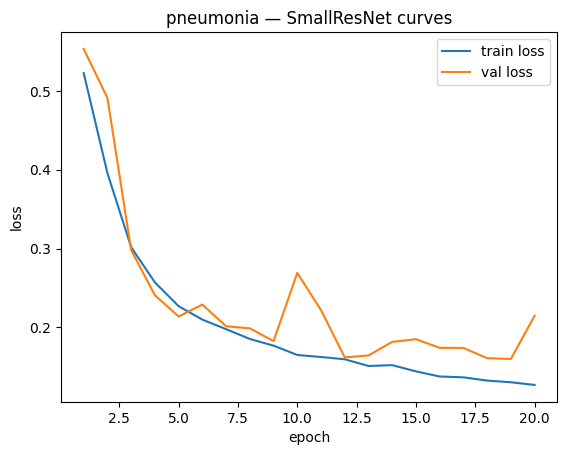

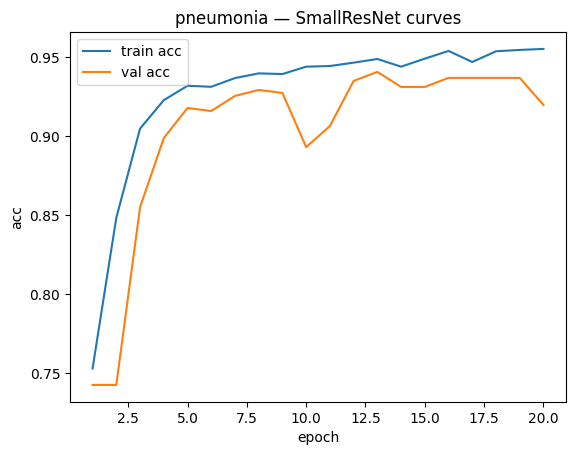

In [27]:
num_epochs = 20
lr = 1e-4

for ds in ['pneumonia']:
    print(f"\n==== {ds.upper()} — SmallResNet ====")

    res_res = train(
        dataset_name=ds,
        cfg=CFG,
        model_kind='resnet',
        epochs=num_epochs,
        batch_size=CFG.batch_size,
        lr=lr
    )

    if ds not in experiments:
        experiments[ds] = {}
    experiments[ds]['resnet'] = res_res

    plot_curves(res_res['hist'], title=f"{ds} — SmallResNet curves")


==== BREAST — SmallCNN ====
Starting training: breast (ultrasound) | Model: CNN


Ep 1/50 | train_loss: 0.6221 | trian_acc: 0.714 | val_loss: 0.6728 | val_acc: 0.718 | AUC: 0.564


Ep 2/50 | train_loss: 0.5855 | trian_acc: 0.709 | val_loss: 0.6820 | val_acc: 0.615 | AUC: 0.601


Ep 3/50 | train_loss: 0.5561 | trian_acc: 0.749 | val_loss: 0.6977 | val_acc: 0.500 | AUC: 0.624


Ep 4/50 | train_loss: 0.5324 | trian_acc: 0.751 | val_loss: 0.7105 | val_acc: 0.423 | AUC: 0.639


...

Ep 14/50 | train_loss: 0.4951 | trian_acc: 0.782 | val_loss: 0.6292 | val_acc: 0.615 | AUC: 0.830


Ep 15/50 | train_loss: 0.5038 | trian_acc: 0.764 | val_loss: 0.5369 | val_acc: 0.705 | AUC: 0.812


Ep 16/50 | train_loss: 0.4775 | trian_acc: 0.789 | val_loss: 0.5114 | val_acc: 0.692 | AUC: 0.748


Ep 17/50 | train_loss: 0.4949 | trian_acc: 0.771 | val_loss: 0.5257 | val_acc: 0.667 | AUC: 0.734


Ep 18/50 | train_loss: 0.4899 | trian_acc: 0.760 | val_loss: 0.4766 | val_acc: 0.756 | AUC: 0.787
Early stopping triggered at epoch 18
TEST | loss 0.6302 acc 0.622 auc 0.805


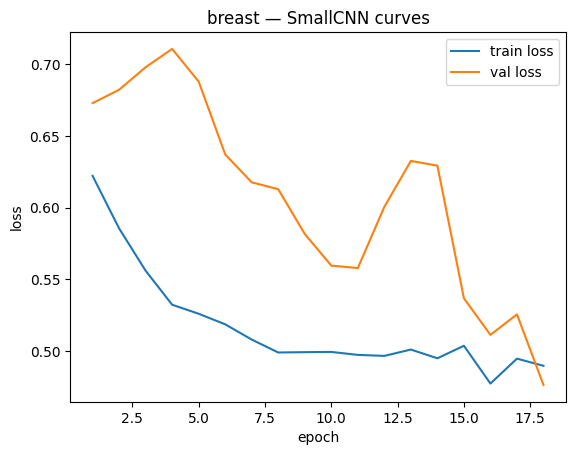

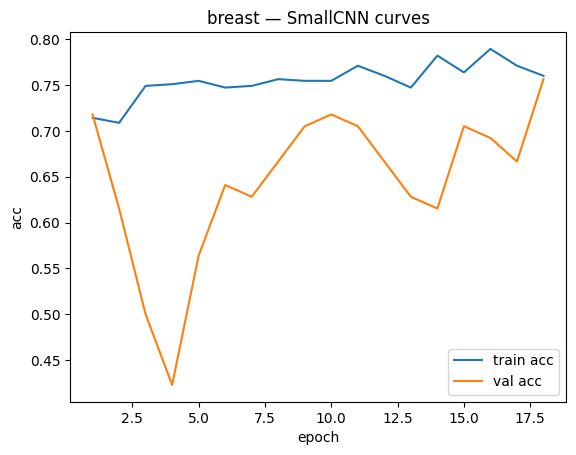

In [28]:
num_epochs = 50
batch_size = 256

for ds in ['breast']:
    print(f"\n==== {ds.upper()} — SmallCNN ====")

    res_cnn = train(
        dataset_name=ds,
        cfg=CFG,
        model_kind='cnn',
        epochs=num_epochs,
        batch_size=CFG.batch_size,
        lr=1e-3
    )

    if ds not in experiments:
        experiments[ds] = {}
    experiments[ds]['cnn'] = res_cnn

    plot_curves(res_cnn['hist'], title=f"{ds} — SmallCNN curves")


==== BREAST — SmallResNet ====
Starting training: breast (ultrasound) | Model: RESNET


Ep 1/50 | train_loss: 0.6553 | trian_acc: 0.659 | val_loss: 0.6355 | val_acc: 0.718 | AUC: 0.533


Ep 2/50 | train_loss: 0.5843 | trian_acc: 0.723 | val_loss: 0.5770 | val_acc: 0.718 | AUC: 0.620


Ep 3/50 | train_loss: 0.5565 | trian_acc: 0.736 | val_loss: 0.5374 | val_acc: 0.756 | AUC: 0.692


Ep 4/50 | train_loss: 0.5442 | trian_acc: 0.744 | val_loss: 0.5288 | val_acc: 0.731 | AUC: 0.709


...

Ep 25/50 | train_loss: 0.4131 | trian_acc: 0.833 | val_loss: 0.3566 | val_acc: 0.859 | AUC: 0.886


Ep 26/50 | train_loss: 0.3981 | trian_acc: 0.830 | val_loss: 0.4963 | val_acc: 0.846 | AUC: 0.808


Ep 27/50 | train_loss: 0.4100 | trian_acc: 0.821 | val_loss: 0.3645 | val_acc: 0.859 | AUC: 0.875


Ep 28/50 | train_loss: 0.4022 | trian_acc: 0.832 | val_loss: 0.4098 | val_acc: 0.885 | AUC: 0.850


Ep 29/50 | train_loss: 0.3961 | trian_acc: 0.824 | val_loss: 0.3666 | val_acc: 0.885 | AUC: 0.866
Early stopping triggered at epoch 29
TEST | loss 0.3892 acc 0.853 auc 0.861


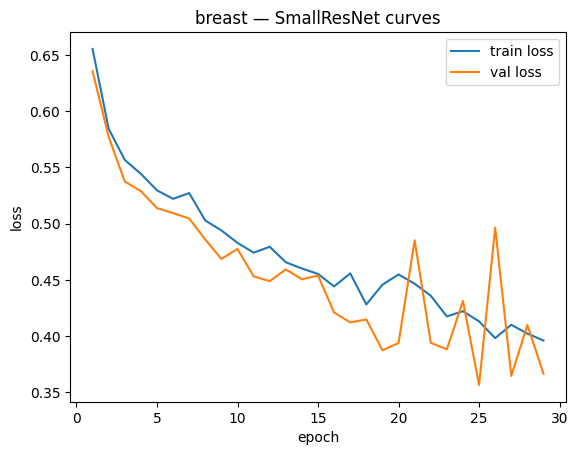

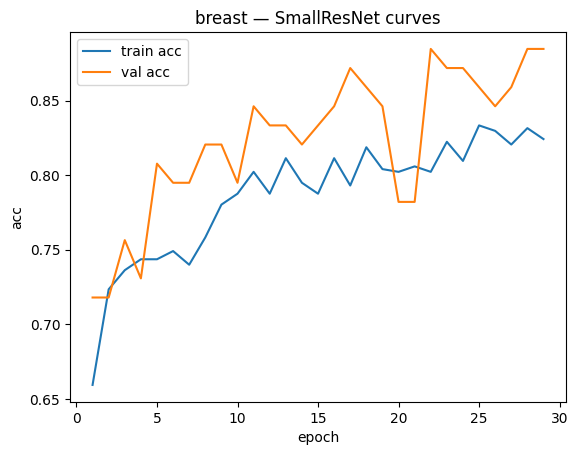

In [29]:
num_epochs = 50
lr = 1e-4

for ds in ['breast']:
    print(f"\n==== {ds.upper()} — SmallResNet ====")

    res_res = train(
        dataset_name=ds,
        cfg=CFG,
        model_kind='resnet',
        epochs=num_epochs,
        batch_size=30,
        lr=lr
    )

    if ds not in experiments:
        experiments[ds] = {}
    experiments[ds]['resnet'] = res_res

    plot_curves(res_res['hist'], title=f"{ds} — SmallResNet curves")


## 10) Evaluation: Confusion Matrices, ROC Curves

This block iterates over datasets and models from previous experiments, prints test metrics, and visualizes performance. It includes:

- Confusion matrices (raw counts and normalized)

- ROC curve for binary classification

It allows you to compare models and datasets, to figure out strengths, weaknesses.

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

def evaluate_and_plot(experiments):
    """Loop through each dataset and model results.
    Extract predictions, probabilities, and targets.
    Plot confusion matrices (both raw and normalized) vertically.
    If binary classification, plot ROC curve at the bottom."""

    for ds_name, models in experiments.items():
        print(f"\n{'='*20} DATASET: {ds_name.upper()} {'='*20}")

        for model_name, res in models.items():
            if res is None:
                continue

            print(f"\n--- Model: {model_name.upper()} ---")

            metrics = res['test_metrics']
            print(f"Test metrics: Loss: {metrics['loss']:.4f} | Acc: {metrics['acc']:.4f} | AUC: {metrics['auc']:.4f}")

            y_true = res['test_targets']
            probs = res['test_probs']
            y_pred = np.argmax(probs, axis=1)
            n_classes = res['n_classes']

            is_binary = (n_classes == 2)

            n_rows = 3 if is_binary else 2

            fig, axes = plt.subplots(n_rows, 1, figsize=(6, 5 * n_rows))

            cm = confusion_matrix(y_true, y_pred)
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)

            disp.plot(ax=axes[0], cmap='viridis', values_format='d', colorbar=True)
            axes[0].set_title(f"{model_name.upper()} - CM (Raw Counts)")

            cm_norm = confusion_matrix(y_true, y_pred, normalize='true')
            disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm)

            disp_norm.plot(ax=axes[1], cmap='viridis', values_format='.2f', colorbar=True)
            axes[1].set_title(f"{model_name.upper()} - CM (Normalized)")

            if is_binary:
                fpr, tpr, _ = roc_curve(y_true, probs[:, 1])
                roc_auc = auc(fpr, tpr)

                axes[2].plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.3f}')
                axes[2].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
                axes[2].set_xlim([0.0, 1.0])
                axes[2].set_ylim([0.0, 1.05])
                axes[2].set_xlabel('False Positive Rate')
                axes[2].set_ylabel('True Positive Rate (Recall)')
                axes[2].set_title(f"{model_name.upper()} - ROC Curve")
                axes[2].legend(loc="lower right")
                axes[2].grid(True, alpha=0.3)

            plt.tight_layout()
            plt.show()




==================== DATASET: PNEUMONIA ====================

--- Model: CNN ---
Test metrics: Loss: 0.3371 | Acc: 0.8686 | AUC: 0.9397


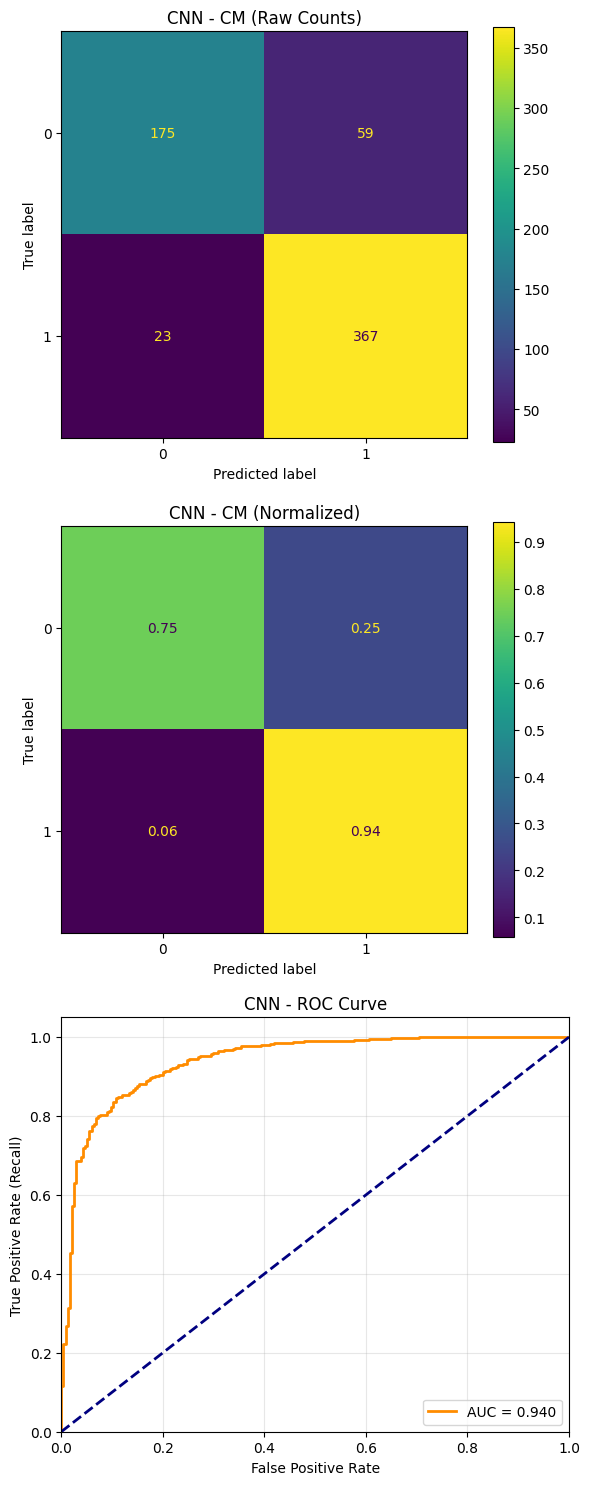


--- Model: RESNET ---
Test metrics: Loss: 0.2569 | Acc: 0.8974 | AUC: 0.9559


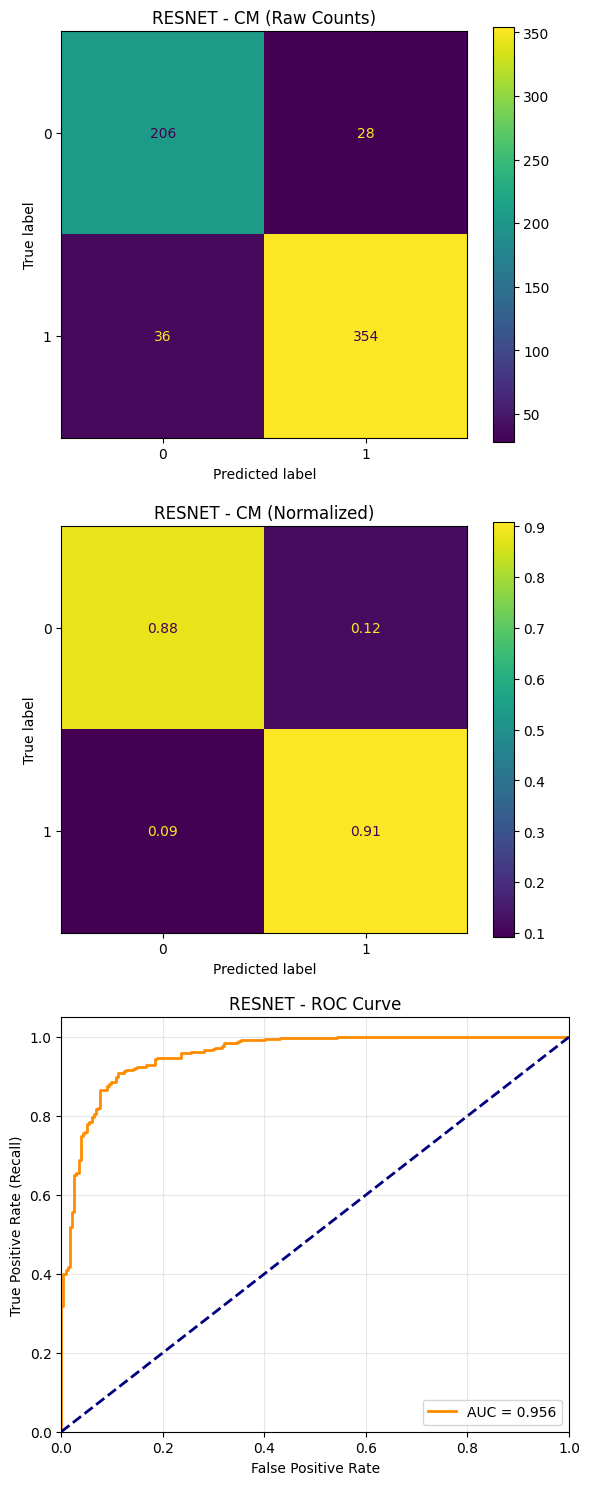


==================== DATASET: BREAST ====================

--- Model: CNN ---
Test metrics: Loss: 0.6302 | Acc: 0.6218 | AUC: 0.8045


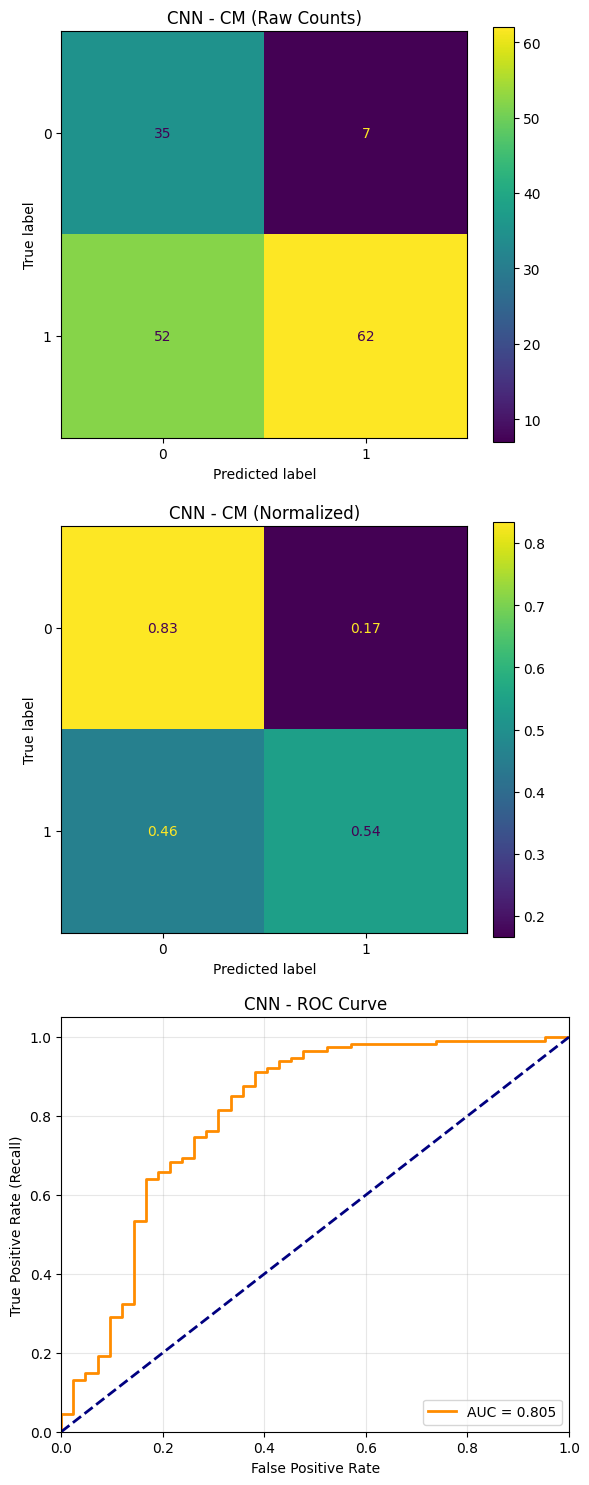


--- Model: RESNET ---
Test metrics: Loss: 0.3892 | Acc: 0.8526 | AUC: 0.8613


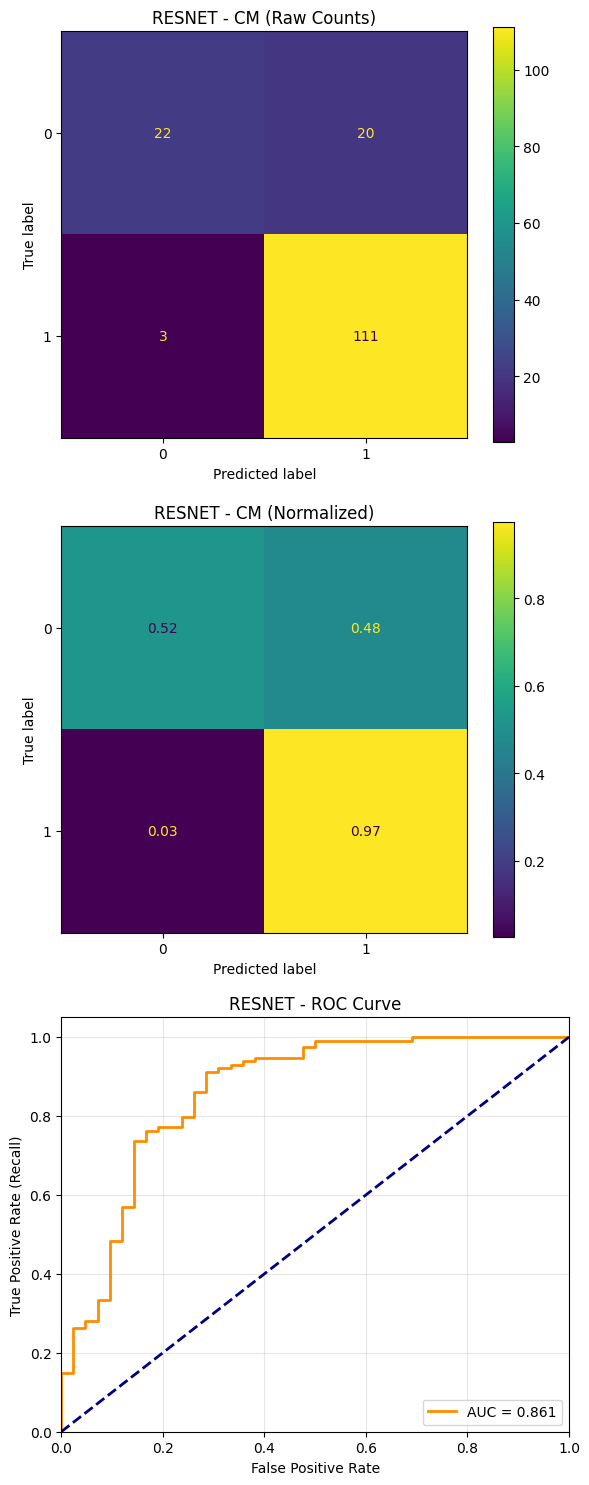

In [32]:
evaluate_and_plot(experiments)

**Question:** Why might the ROC curve be less informative for highly imbalanced datasets?

**Answer:**

The Deception

In highly imbalanced datasets with overwhelming negative class prevalence, the ROC curve can be misleading. The False Positive Rate calculation (FPR = FP/TotalNegatives) uses the large negative count as denominator. When the negative class is massive (e.g., 95% of data), even numerous False Positives yield a very small FPR, making the ROC curve appear excellent (hugging the top-left corner) despite the model generating many false alarms relative to the scarce positive cases.

Alternative Metric

Precision-Recall curves provide clearer insights for imbalanced scenarios by directly focusing on positive class prediction quality, showing how many predicted positives are actually correct.

**Question:** Comparing the confusion matrices and ROC curves, which model seems to perform better across datasets, and what can you infer about differences in dataset difficulty?

**Answer:**

Model Comparison

SmallResNet slightly outperforms SmallCNN across datasets. Skip connections enable deeper feature learning without degradation, yielding marginally higher AUC scores and improved sensitivity (Recall). However, on the challenging BreastMNIST dataset, the performance gap narrows, with ResNet potentially showing overfitting signs (higher train/validation loss variance compared to CNN).

Dataset Difficulty Assessment

PneumoniaMNIST (Easier): Both models achieve high AUC (>0.90) with clean confusion matrices. X-ray lung images contain distinct, high-contrast features (opacity patterns) that CNNs readily detect.

BreastMNIST (Harder): Both models struggle with lower AUC (~0.80-0.86) and exhibit more False Positives/Negatives in confusion matrices. Ultrasound imaging presents greater difficulty due to speckle noise, low contrast, and subtle textural differences between benign and malignant tumors. Class imbalance further challenges the models by biasing them toward predicting “Benign,” necessitating more careful tuning than the Pneumonia dataset requires.



